# EMQA_L3_dow_effect

**Weekly calendar in the Romanian daily price change, 2019-01-01 to 2026-10-31**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_dow_effect/EMQA_L3_dow_effect.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## The weekly calendar

Mean equation, estimated by ordinary least squares (OLS):

$$r_t=c+\sum_{k=1}^{7}\phi_k r_{t-k}+\sum_{j=2}^{7}\delta_j D_{j,t}+\varepsilon_t$$

$D_{j,t}=1$ if day $t$ is weekday $j$. The residuals $\varepsilon_t$ are the shocks modelled in the rest of the lecture.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


### Numbers on the slide

In [6]:
rr = r.dropna()
DOW = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow = rr.groupby(rr.index.dayofweek).mean()
for k, v in dow.items():
    slide(f'mean change on {DOW[k]}, %', f'mean.dow_pct.{DOW[k]}', v, 2)
sd_raw, sd_res = rr.loc[E_PCT.index].std(), E_PCT.std()
slide('R^2 of the mean equation', 'mean.r2_pct', M_PCT.rsquared, 3)
slide('std. dev. of the raw change, %', 'mean.sd_raw', sd_raw, 2)
slide('std. dev. after the mean equation, %', 'mean.sd_res', sd_res, 2)

mean change on Mon, %                                      38.29   [mean.dow_pct.Mon]
mean change on Tue, %                                      4.42   [mean.dow_pct.Tue]
mean change on Wed, %                                      0.57   [mean.dow_pct.Wed]
mean change on Thu, %                                      -0.95   [mean.dow_pct.Thu]
mean change on Fri, %                                      -4.45   [mean.dow_pct.Fri]
mean change on Sat, %                                      -18.17   [mean.dow_pct.Sat]
mean change on Sun, %                                      -19.2   [mean.dow_pct.Sun]
R^2 of the mean equation                                   0.499   [mean.r2_pct]
std. dev. of the raw change, %                             28.27   [mean.sd_raw]
std. dev. after the mean equation, %                       20.0   [mean.sd_res]


### Chart

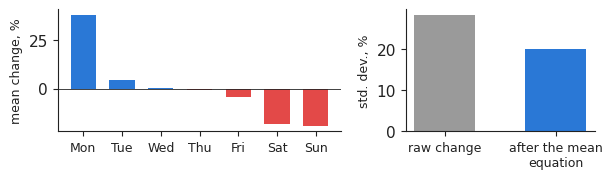

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.0), gridspec_kw={'width_ratios': [1.5, 1]})
axs[0].bar(range(7), dow.values, color=[PAL['c8'] if v < 0 else PAL['RO'] for v in dow.values], width=0.65)
axs[0].axhline(0, color='#222222', lw=0.6)
axs[0].set_xticks(range(7))
axs[0].set_xticklabels(DOW, fontsize=9)
axs[0].set_ylabel('mean change, %', fontsize=9)
axs[1].bar([0, 1], [round(sd_raw, 2), round(sd_res, 2)], color=['#9a9a9a', C_PCT], width=0.55)
axs[1].set_xticks([0, 1])
axs[1].set_xticklabels(['raw change', 'after the mean\nequation'], fontsize=9)
axs[1].set_ylabel('std. dev., %', fontsize=9)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig('dow_effect.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()